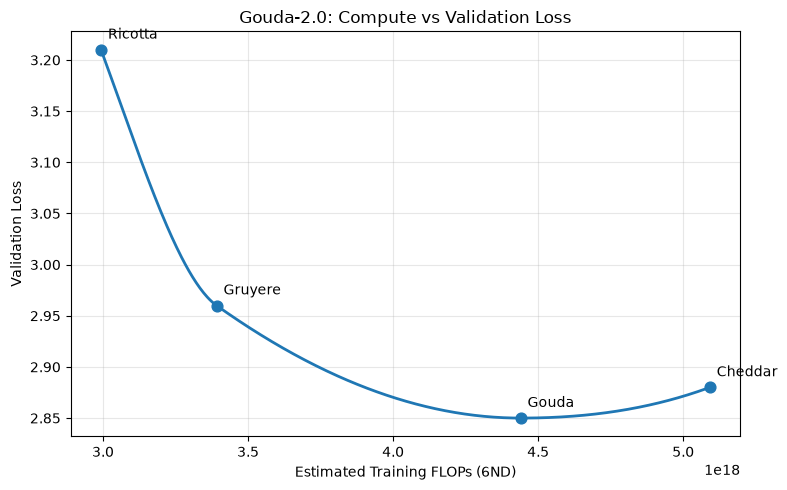

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import PchipInterpolator

models = {
    "Ricotta": (24.1e6 * 20701e6 * 6, 3.21),
    "Gruyere": (62.9e6 * 8987e6 * 6, 2.96),
    "Gouda": (132.2e6 * 5597e6 * 6, 2.85),
    "Cheddar": (302.1e6 * 2809e6 * 6, 2.88),
}

models = dict(sorted(models.items(), key=lambda x: x[1][0]))
x = np.array([v[0] for v in models.values()])
y = np.array([v[1] for v in models.values()])

# Smooth interpolation
spline = PchipInterpolator(x, y)
x_smooth = np.linspace(x.min(), x.max(), 500)
y_smooth = spline(x_smooth)

plt.figure(figsize=(8, 5))
plt.plot(x_smooth, y_smooth, linewidth=2)
plt.scatter(x, y, s=60, zorder=3)

for name, (compute, loss) in models.items():
    plt.annotate(name, (compute, loss),
                 xytext=(5, 8), textcoords="offset points")

plt.xlabel("Estimated Training FLOPs (6ND)")
plt.ylabel("Validation Loss")
plt.title("Gouda-2.0: Compute vs Validation Loss")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()